# Two-branch Voigt circuit: exploratory SPEIS audit

Model: $Z=R_s+\sum_{i=1}^{2}(1/R_i+Q_i(j2\pi f)^{\alpha_i})^{-1}$. Branches are ordered by fitted peak frequency for display only; that ordering is **not** a physical assignment and can exchange as bias changes. The model-derived effective capacitance $C_i=Q_i^{1/\alpha_i}R_i^{(1-\alpha_i)/\alpha_i}$ is not established to be a depletion capacitance. No semiconductor type or flat-band voltage is inferred.

All eligible EIS rows, not a plotting sample, are processed. Comparison uses the same explicit frequency and $-\mathrm{Im}(Z)\geq0$ mask, sign, and modulus weights. AICc assumes independent identically distributed weighted real and imaginary residuals; data-dependent weights and correlations can invalidate that interpretation. Fit covariance is a local residual-scaled approximation, not measurement uncertainty. Temperature 298.15 K is assumed context, not a monitored value. The bias correction is a user-specified convention, not a verified internal potential.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from speis_fitting import group_spectra, impedance_rcpe, inverse_capacitance_squared, linear_regression, carrier_density
from voigt_fitting import (load_eis_csv, fit_mask, compare_models, impedance_voigt,
                           crossing_flags, DEFAULT_BOUNDS)

FILE_PATH = Path('BiSI - IV_EIS_IV_1to-1_Electrode12_30m_more_time_02_SPEIS_C03.csv')
AREA_CM2, RELATIVE_PERMITTIVITY, TEMPERATURE_K = 0.09, 38.0, 298.15
OFFSET_V = -0.2  # convention: corrected = recorded Au-vs-FTO - 0.2 V
CHUNK_SIZE = 50_000
FREQ_MIN_HZ, FREQ_MAX_HZ = None, None  # inclusive
FIT_OPTIONS = dict(bounds=DEFAULT_BOUNDS, n_starts=12, max_nfev=2500)
PAGE = 0                  # zero-based page for tables and spectrum plots
PAGE_SIZE = 4             # <= 8 to keep output bounded
TABLE_PAGE_SIZE = 25
REVIEW = dict(branch=None, justification='', voltage_range_corrected=None,
              confirm_branch_and_range=False, confirm_density_assumptions=False)
# After inspecting plots and QC: branch=1 (lower peak) or 2 (higher peak),
# nonempty justification, inclusive corrected range=(min,max), confirm_branch_and_range=True.
# Density additionally requires confirm_density_assumptions=True, affirming the
# depletion-model, active-area and permittivity assumptions independently.
if not FILE_PATH.is_file():
    raise FileNotFoundError(FILE_PATH.resolve())
if not 1 <= PAGE_SIZE <= 8 or PAGE < 0:
    raise ValueError('PAGE must be nonnegative and PAGE_SIZE in 1..8')
print(f'Assumed area {AREA_CM2} cm², εr={RELATIVE_PERMITTIVITY}, temperature {TEMPERATURE_K} K (context only).')
print(f'Bias: measured Au vs FTO; corrected = measured {OFFSET_V:+.2f} V (convention only).')

Assumed area 0.09 cm², εr=38.0, temperature 298.15 K (context only).
Bias: measured Au vs FTO; corrected = measured -0.20 V (convention only).


## 1. Chunked acquisition audit and contiguous sweeps

Zero-frequency rows may be non-EIS acquisition points; negative or nonnumeric frequencies cannot be reliably grouped and are counted with a bounded source-row sample. Positive-frequency rows, including invalid impedance or voltage, are retained in sweeps. `_row` is the zero-based data record ordinal after the header. A frequency reset or cycle change defines a new spectrum, not equal-voltage grouping. Completeness is unverified without independently supplied expectations.

In [2]:
eis, input_audit, ungroupable_sample = load_eis_csv(FILE_PATH, chunksize=CHUNK_SIZE)
spectra = group_spectra(eis)
print('Input record counts:', input_audit)
print(f'{len(spectra)} contiguous spectra; zero-frequency rows are not assumed to be invalid EIS.')
if len(ungroupable_sample):
    print('First 20 ungroupable negative/nonfinite frequency rows:')
    display(ungroupable_sample)
if not spectra:
    print('No positive-frequency spectra: analysis stops cleanly.')

Input record counts: {'total': 375172, 'positive_frequency': 1386, 'zero_frequency': 373786, 'negative_frequency': 0, 'invalid_frequency': 0, 'invalid_positive_impedance': 0, 'invalid_positive_voltage': 0}
21 contiguous spectra; zero-frequency rows are not assumed to be invalid EIS.


## 2. Bounded multistart fits and model comparison

Positive parameters are optimized in logarithmic coordinates; both exponents are bounded in $(0,1]$. Starts are deterministic and dispersed. Peak separation, out-of-band peaks, near-optimal alternative parameters after label exchange, bounds, Jacobian conditioning, and fit residuals are heuristic QC warnings, not proofs of uniqueness. Flagged model-derived capacitances remain visible for audit but are not automatically eligible for regression. Uncertainty is suppressed when the local covariance is unreliable. The 4- and 7-parameter AICc values use $2n$ weighted residual components; AICc is unavailable for insufficient observations.

In [5]:
fits = {}
for spectrum in spectra:
    mask = fit_mask(spectrum, FREQ_MIN_HZ, FREQ_MAX_HZ)
    fits[spectrum.spectrum_id] = (mask, *compare_models(spectrum, mask=mask, **FIT_OPTIONS))
crossings = crossing_flags([(s, fits[s.spectrum_id][2]) for s in spectra])
for sid in crossings:
    fits[sid][2].flags.append('possible_branch_crossing')

records = []
for s in spectra:
    mask, one, two, comp = fits[s.spectrum_id]
    p = two.parameters if two.success else np.full(7, np.nan)
    records.append(dict(spectrum_id=s.spectrum_id, cycle=s.cycle, measured_V=s.voltage_v,
        corrected_V=s.voltage_v+OFFSET_V, voltage_spread_V=s.voltage_spread_v,
        n_total=len(s.data), n_used=int(mask.sum()), n_excluded=int((~mask).sum()),
        single_ok=one.success, voigt_ok=two.success,
        Rs=p[0], R_low=p[1], Q_low=p[2], alpha_low=p[3], R_high=p[4], Q_high=p[5], alpha_high=p[6],
        peak_low_Hz=two.peaks_hz[0], peak_high_Hz=two.peaks_hz[1],
        C_low_F=two.capacitances[0], C_high_F=two.capacitances[1],
        C_low_std_F=two.capacitance_stds[0], C_high_std_F=two.capacitance_stds[1],
        single_C_F=one.capacitance_f, delta_Rs_vs_single=p[0]-(one.parameters[0] if one.success else np.nan),
        condition=two.jacobian_condition, starts=two.starts_converged,
        near_starts=two.near_optimal_starts, flags='; '.join(two.flags),
        single_flags='; '.join(one.flags), **comp))
results = pd.DataFrame(records)
print(f'Fitted {sum(fits[s.spectrum_id][2].success for s in spectra)}/{len(spectra)} two-branch and '
      f'{sum(fits[s.spectrum_id][1].success for s in spectra)}/{len(spectra)} single-branch spectra.')
print('All source rows and masks remain accessible in spectra and fits; tables below are paged.')
if not results.empty:
    page = results.iloc[PAGE*TABLE_PAGE_SIZE:(PAGE+1)*TABLE_PAGE_SIZE]
    print('Fit parameters, frequency-ordered branches:')
    display(page[['spectrum_id','measured_V','corrected_V','Rs','R_low','Q_low','alpha_low',
                  'R_high','Q_high','alpha_high']])
    print('Capacitances (F), peak frequencies (Hz), and QC:')
    display(page[['spectrum_id','peak_low_Hz','peak_high_Hz','C_low_F','C_low_std_F',
                  'C_high_F','C_high_std_F','condition','flags']])
    print('Same-mask comparisons (AICc is assumption-dependent):')
    display(page[['spectrum_id','n_used','n_excluded','single_relative_rmse','voigt_relative_rmse',
                  'single_weighted_rss','voigt_weighted_rss','single_aicc','voigt_aicc']])
    print('QC flag counts:')
    display(results['flags'].str.split('; ').explode().value_counts().head(20))

Fitted 21/21 two-branch and 21/21 single-branch spectra.
All source rows and masks remain accessible in spectra and fits; tables below are paged.
Fit parameters, frequency-ordered branches:


,spectrum_id,measured_V,corrected_V,Rs,R_low,Q_low,alpha_low,R_high,Q_high,alpha_high
0,1,-1.000324,-1.200324,10.081475,3796.238016,7.172951e-09,1.000000,149.757773,7.205741e-08,1.0
1,2,-0.900366,-1.100366,10.145218,5848.853144,7.578673e-09,1.000000,355.473290,4.561540e-08,1.0
2,3,-0.800278,-1.000278,10.120347,8803.965000,7.510574e-09,1.000000,415.356953,4.781000e-08,1.0
3,4,-0.700334,-0.900334,10.160109,11948.304980,8.318081e-09,1.000000,1006.956145,2.956077e-08,1.0
4,5,-0.600343,-0.800343,10.121706,16299.358657,8.019167e-09,1.000000,919.788225,3.412737e-08,1.0
5,6,-0.500300,-0.700300,10.136873,21870.959463,8.584519e-09,1.000000,1575.387718,2.675177e-08,1.0
6,7,-0.400324,-0.600324,10.147854,27092.623717,9.427944e-09,1.000000,3137.286953,2.094297e-08,1.0
7,8,-0.300369,-0.500369,10.157539,33294.657316,1.055442e-08,1.000000,4917.784367,1.695663e-08,1.0
8,9,-0.200380,-0.400380,10.114604,35319.396308,1.295719e-08,1.000000,8731.110463,1.320876e-08,1.0
9,10,-0.100321,-0.300321,10.156221,35727.100690,1.603558e-08,0.996542,11361.655352,1.152152e-08,1.0


Capacitances (F), peak frequencies (Hz), and QC:


,spectrum_id,peak_low_Hz,peak_high_Hz,C_low_F,C_low_std_F,C_high_F,C_high_std_F,condition,flags
0,1,5844.789261,14748.644658,7.172951e-09,None,7.205741e-08,None,25302.705896,completeness_unverified; excluded_points; over...
1,2,3590.510947,9815.256233,7.578673e-09,None,4.561540e-08,None,12345.267932,completeness_unverified; excluded_points; over...
2,3,2406.958907,8014.564817,7.510574e-09,None,4.781000e-08,None,8538.589201,completeness_unverified; excluded_points; para...
3,4,1601.366399,5346.799384,8.318081e-09,None,2.956077e-08,None,4785.544101,completeness_unverified; excluded_points; para...
4,5,1217.644011,5070.251115,8.019167e-09,None,3.412737e-08,None,3702.096099,completeness_unverified; excluded_points; para...
5,6,847.688596,3776.418125,8.584519e-09,None,2.675177e-08,None,2397.014053,completeness_unverified; excluded_points; para...
6,7,623.091882,2422.298164,9.427944e-09,None,2.094297e-08,None,2051.424871,completeness_unverified; excluded_points; para...
7,8,452.909302,1908.583027,1.055442e-08,None,1.695663e-08,None,1313.047204,completeness_unverified; excluded_points; para...
8,9,347.773091,1380.030082,1.295719e-08,None,1.320876e-08,None,982.606646,completeness_unverified; excluded_points; para...
9,10,285.093758,1215.818499,1.562553e-08,None,1.152152e-08,None,746.884528,completeness_unverified; excluded_points; para...


Same-mask comparisons (AICc is assumption-dependent):


,spectrum_id,n_used,n_excluded,single_relative_rmse,voigt_relative_rmse,single_weighted_rss,voigt_weighted_rss,single_aicc,voigt_aicc
0,1,42,24,0.087394,0.086892,0.320782,0.317109,-459.189646,-453.189789
1,2,44,22,0.085655,0.084105,0.322819,0.311239,-485.021966,-481.318804
2,3,46,20,0.087371,0.085038,0.351149,0.332650,-503.826900,-501.932387
3,4,47,19,0.086417,0.080905,0.350995,0.307642,-517.036754,-522.576423
4,5,51,15,0.089716,0.083819,0.410497,0.358311,-554.154321,-561.243887
5,6,54,12,0.089766,0.080626,0.435130,0.351033,-587.149649,-603.612665
6,7,57,9,0.086626,0.076097,0.427733,0.330073,-628.374751,-651.232288
7,8,60,6,0.092476,0.076685,0.513112,0.352840,-646.222497,-684.508002
8,9,63,3,0.093341,0.075570,0.548895,0.359786,-676.621824,-723.225396
9,10,62,4,0.100684,0.077319,0.628509,0.370645,-646.965026,-705.820577


QC flag counts:


flags
completeness_unverified     21
excluded_points             21
parameter_at_bound          21
uncertainty_unavailable     21
possible_branch_crossing     9
overlapping_peaks            6
Name: count, dtype: int64

## Compare one- and two-branch fits at every voltage

Each row shows the measured Nyquist spectrum and both fits, followed by their real and imaginary weighted residuals versus frequency. Blue points are used in both fits; red crosses are excluded from both. The curves are drawn through the used frequencies only. Residuals are $100(Z_\mathrm{model}-Z_\mathrm{measured})/\max(|Z_\mathrm{measured}|,\mathrm{floor})$; the imaginary residual uses $\operatorname{Im}(Z)$, not $-\operatorname{Im}(Z)$. Smaller residuals are desirable, especially if their systematic structure decreases.

The summary reports relative RMSE reduction, $\Delta\mathrm{AICc}=\mathrm{AICc}_{2}-\mathrm{AICc}_{1}$ (negative favors the two-branch model under its assumptions), peak separation, converged and near-optimal starts, and QC flags. AICc assumes independent identically distributed weighted residual components; data-dependent weights and correlations can invalidate it. More starts agreeing does not prove a unique solution, and a better fit or a bound at $\alpha=1$ does not by itself prove overfitting. Review flagged, overlapping or unstable branches before physical interpretation. Plots are grouped three spectra per figure; by default up to 24 spectra are shown.

Showing 21 of 21 spectra; start at spectrum index 0.


,spectrum_id,measured_V,corrected_V,used,excluded,single_RMSE_pct,voigt_RMSE_pct,RMSE_reduction_pct,delta_AICc,peak_separation_decades,converged_starts,near_best_starts,voigt_flags
0,1,-1.000324,-1.200324,42,24,8.739379,8.689195,0.574237,5.999857,0.401983,12,2,"completeness_unverified, excluded_points, over..."
1,2,-0.900366,-1.100366,44,22,8.565516,8.410474,1.810071,3.703162,0.436745,12,2,"completeness_unverified, excluded_points, over..."
2,3,-0.800278,-1.000278,46,20,8.737089,8.503833,2.669721,1.894513,0.522411,12,3,"completeness_unverified, excluded_points, para..."
3,4,-0.700334,-0.900334,47,19,8.641744,8.090468,6.379223,-5.539669,0.523603,12,3,"completeness_unverified, excluded_points, para..."
4,5,-0.600343,-0.800343,51,15,8.971599,8.381946,6.572434,-7.089566,0.619509,12,3,"completeness_unverified, excluded_points, para..."
5,6,-0.500300,-0.700300,54,12,8.976620,8.062637,10.181814,-16.463016,0.648844,12,3,"completeness_unverified, excluded_points, para..."
6,7,-0.400324,-0.600324,57,9,8.662617,7.609702,12.154697,-22.857537,0.589676,12,4,"completeness_unverified, excluded_points, para..."
7,8,-0.300369,-0.500369,60,6,9.247631,7.668547,17.075558,-38.285505,0.624700,12,2,"completeness_unverified, excluded_points, para..."
8,9,-0.200380,-0.400380,63,3,9.334140,7.557041,19.038706,-46.603572,0.598593,12,6,"completeness_unverified, excluded_points, para..."
9,10,-0.100321,-0.300321,62,4,10.068386,7.731851,23.206651,-58.855551,0.629881,12,6,"completeness_unverified, excluded_points, para..."


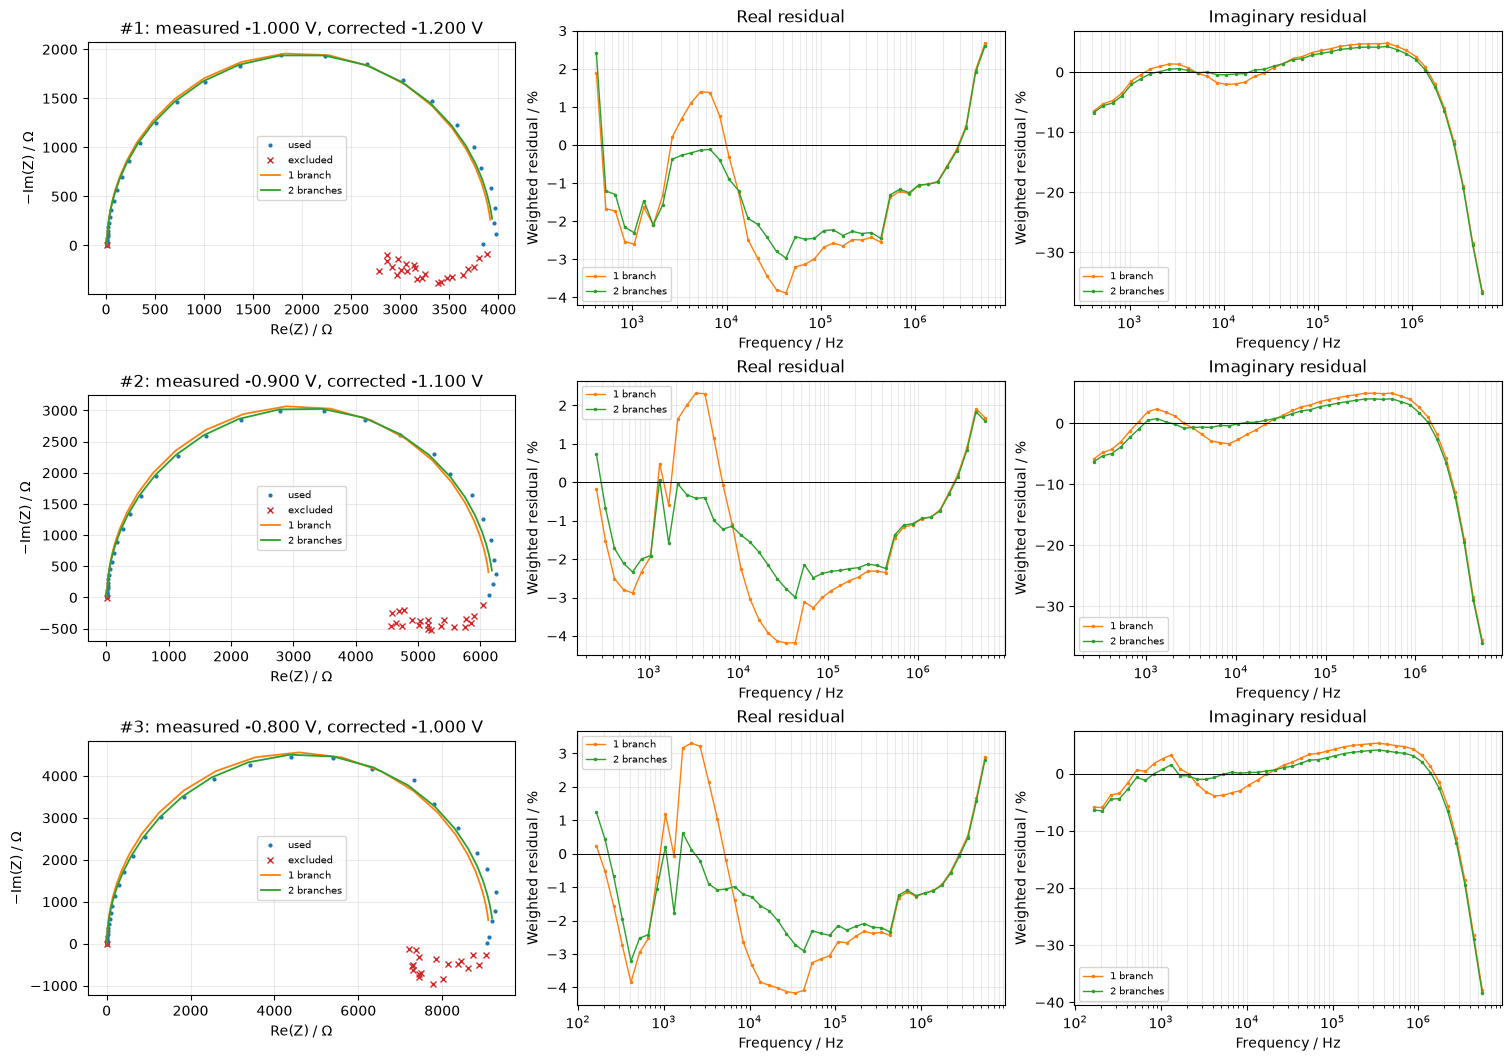

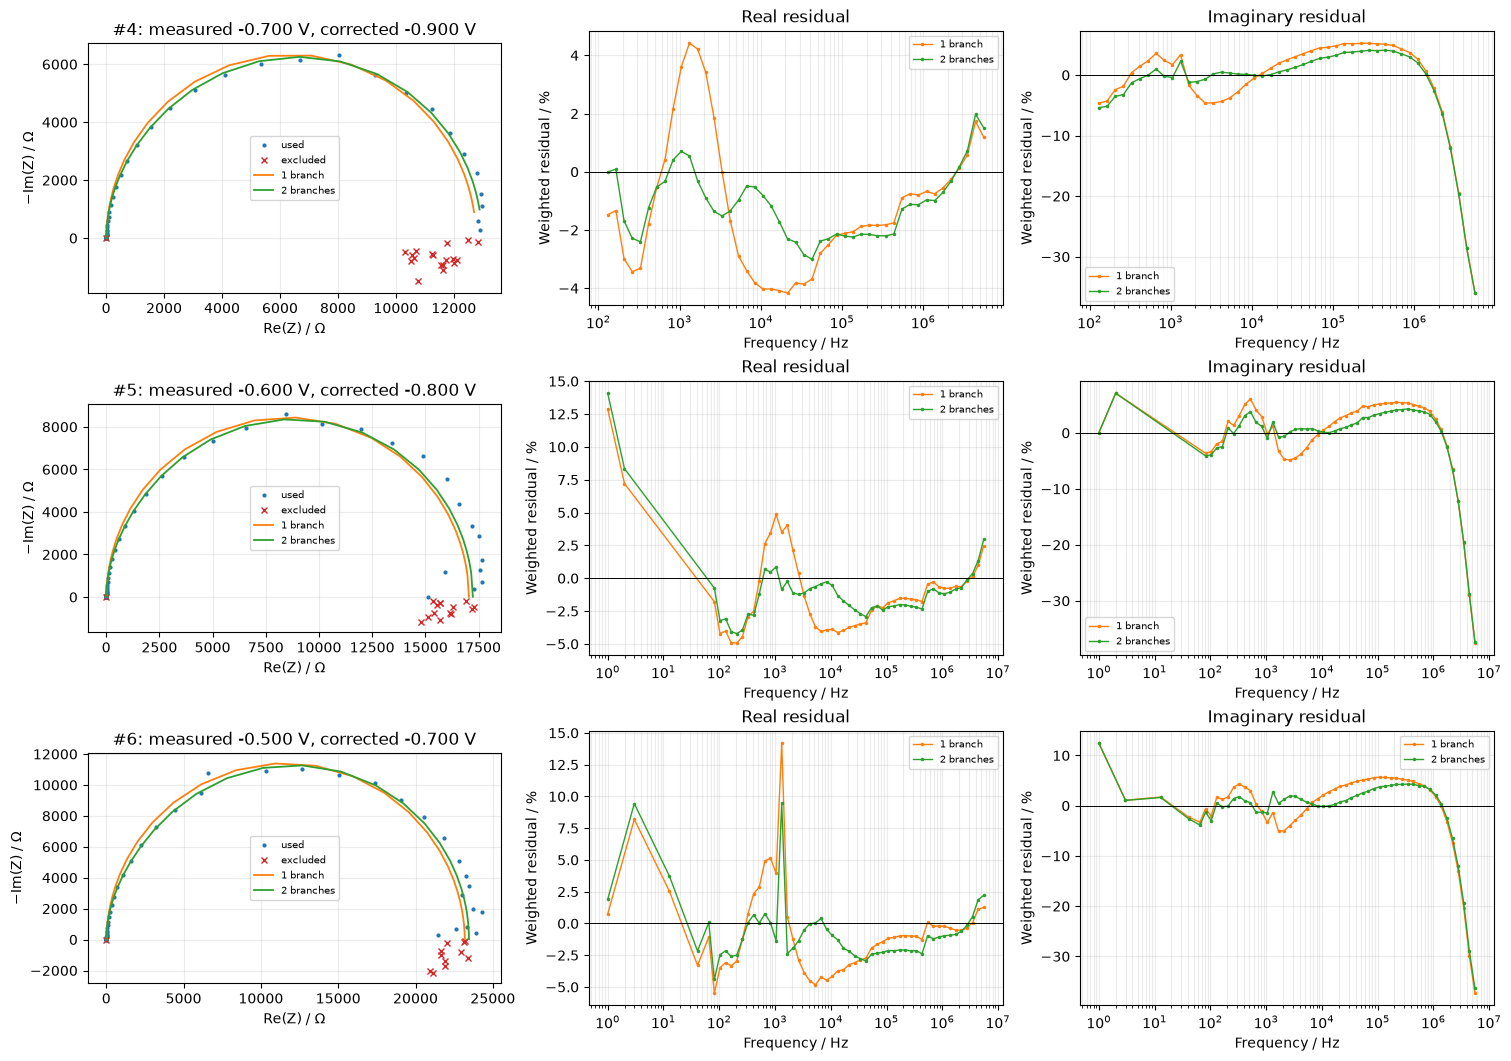

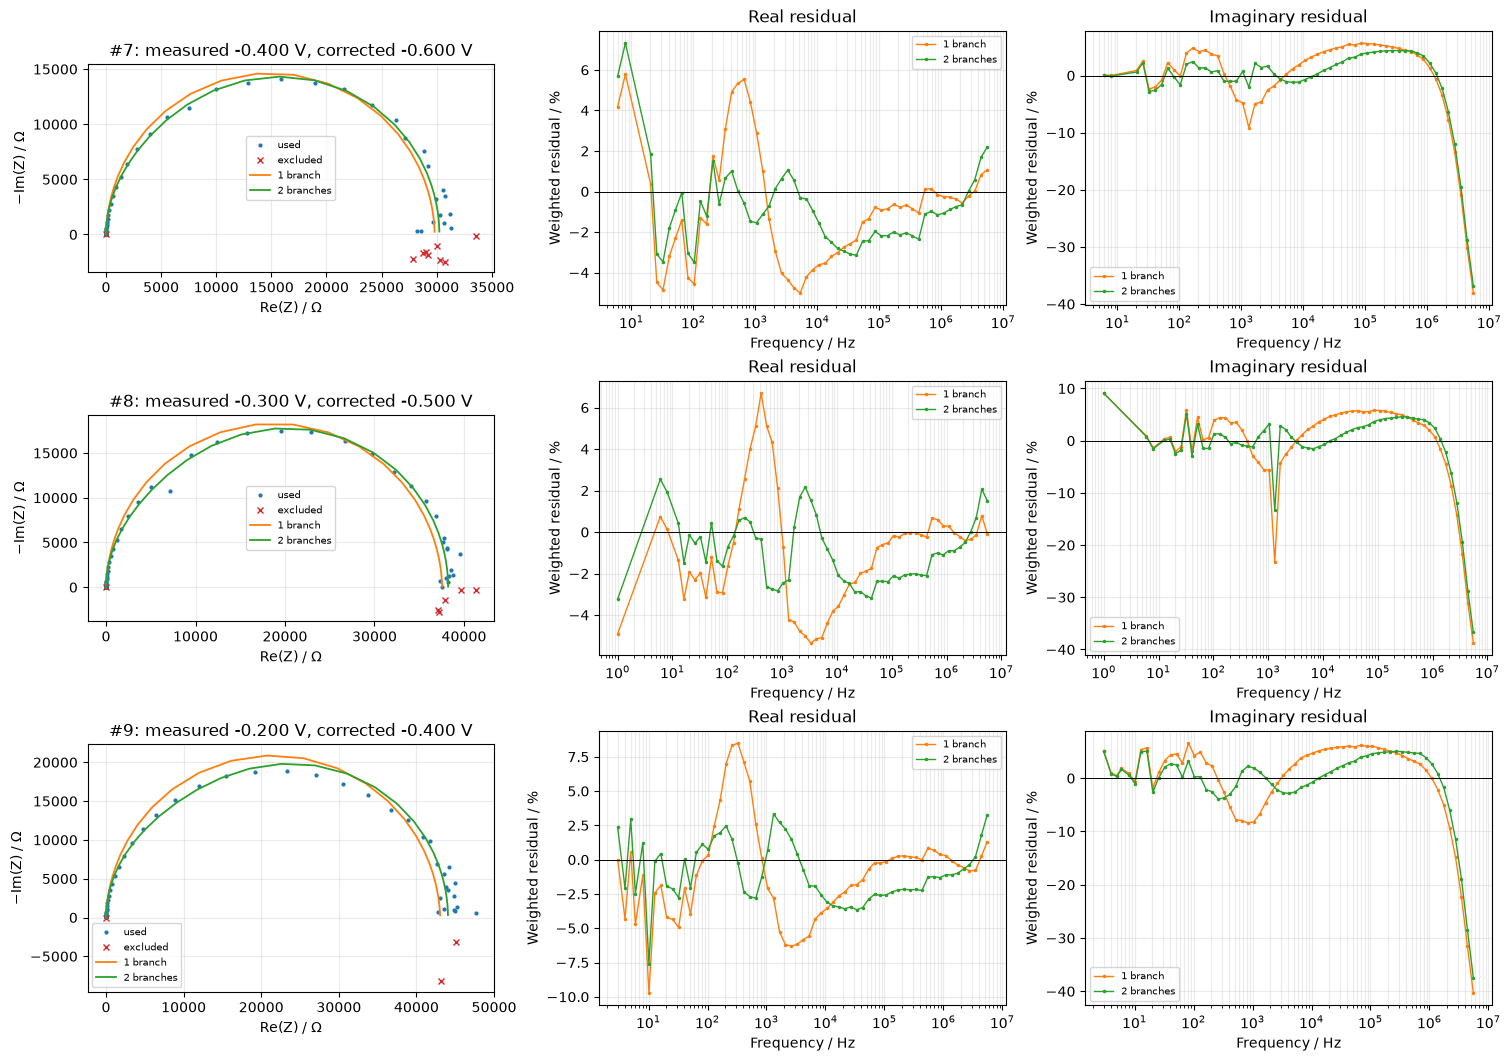

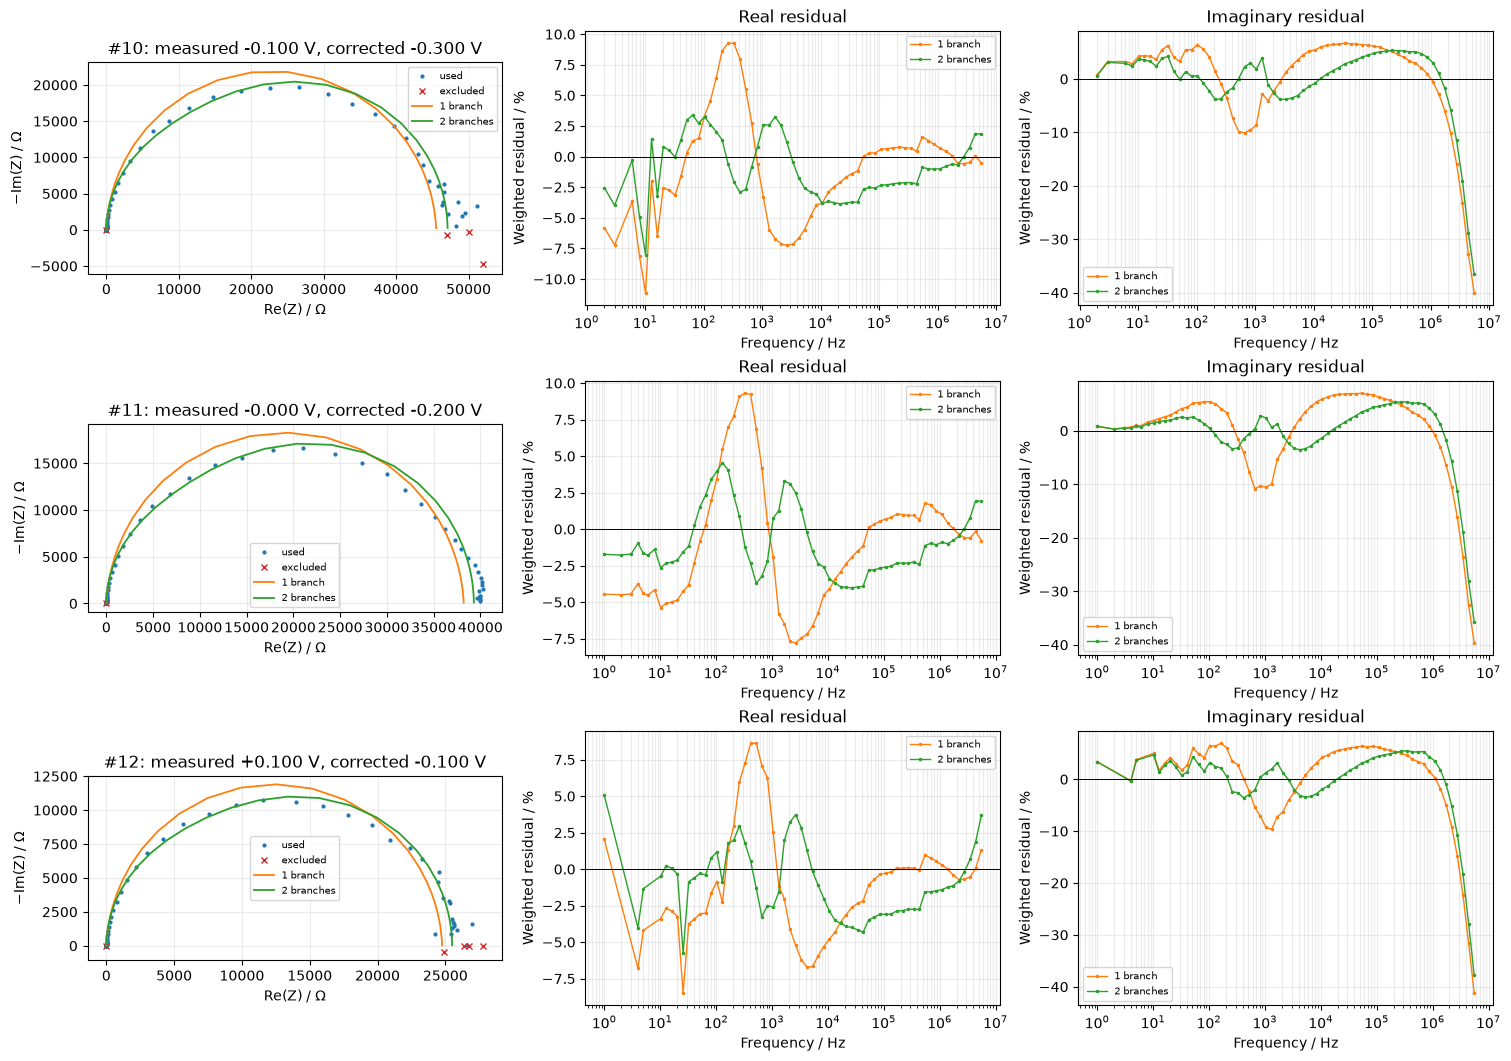

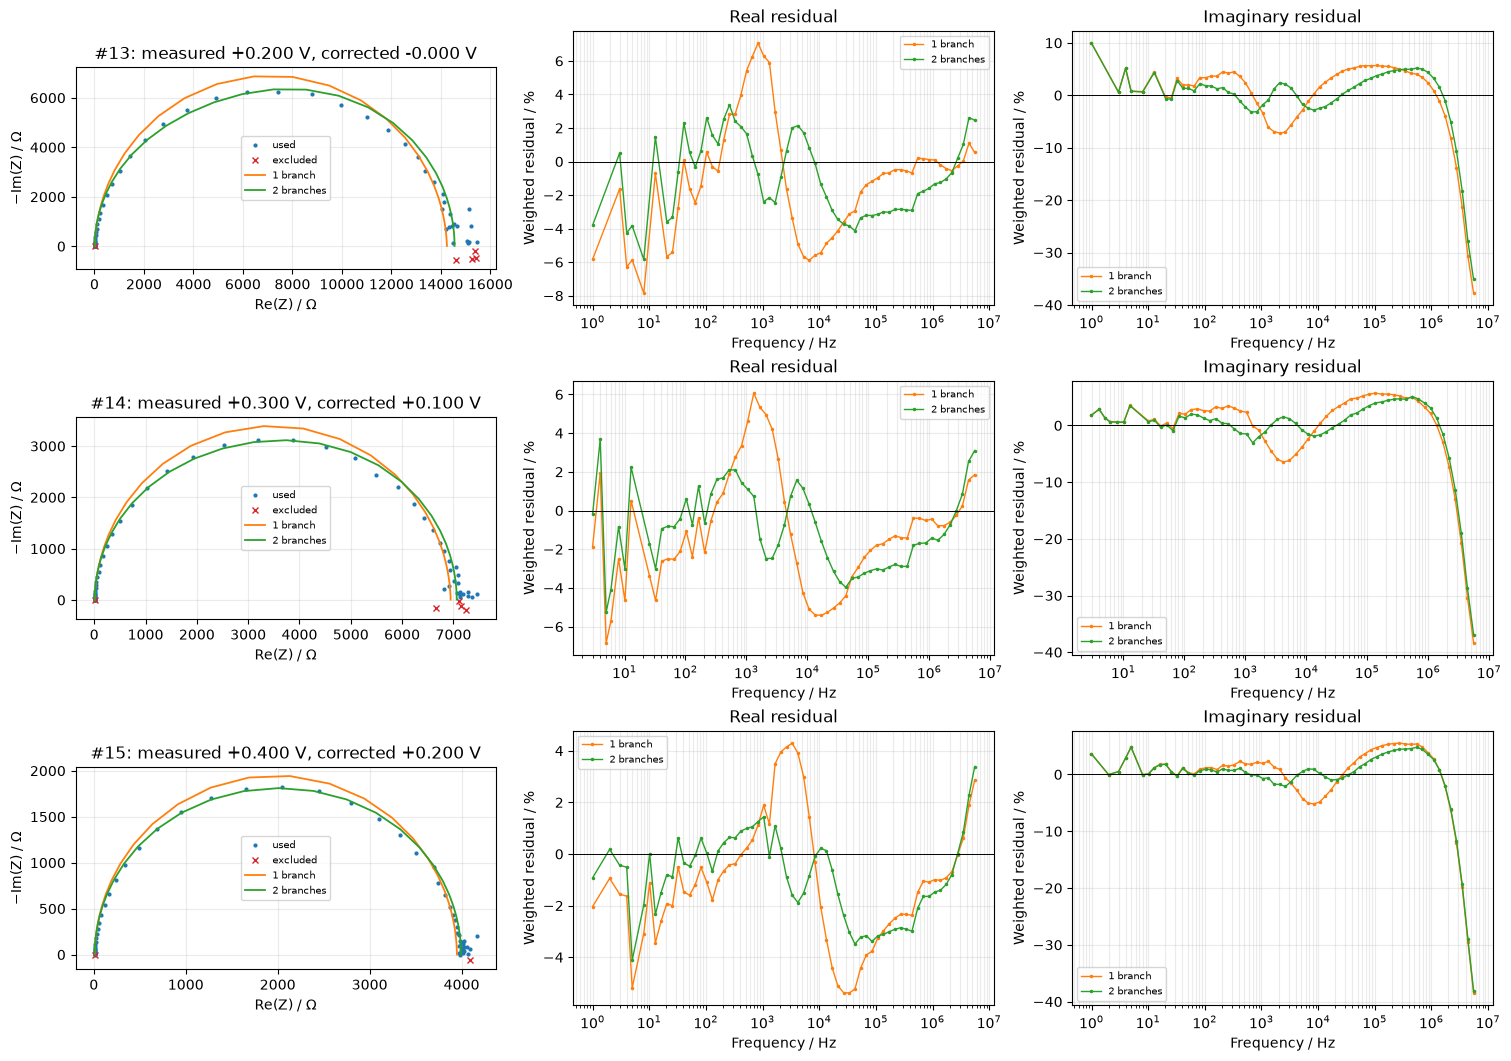

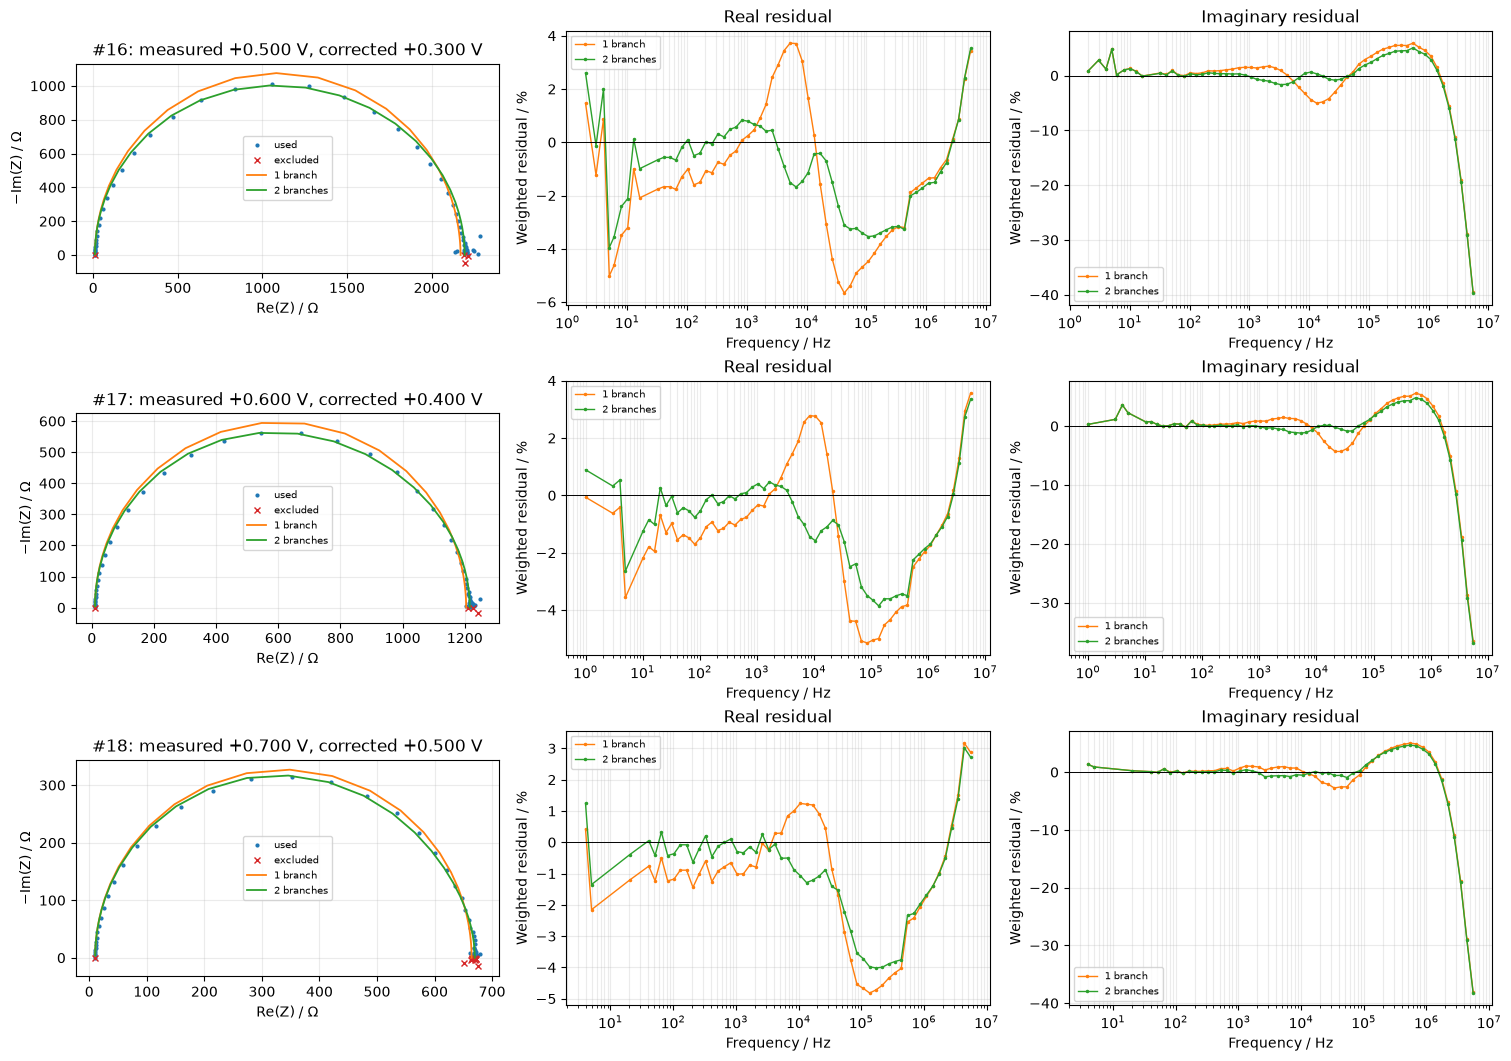

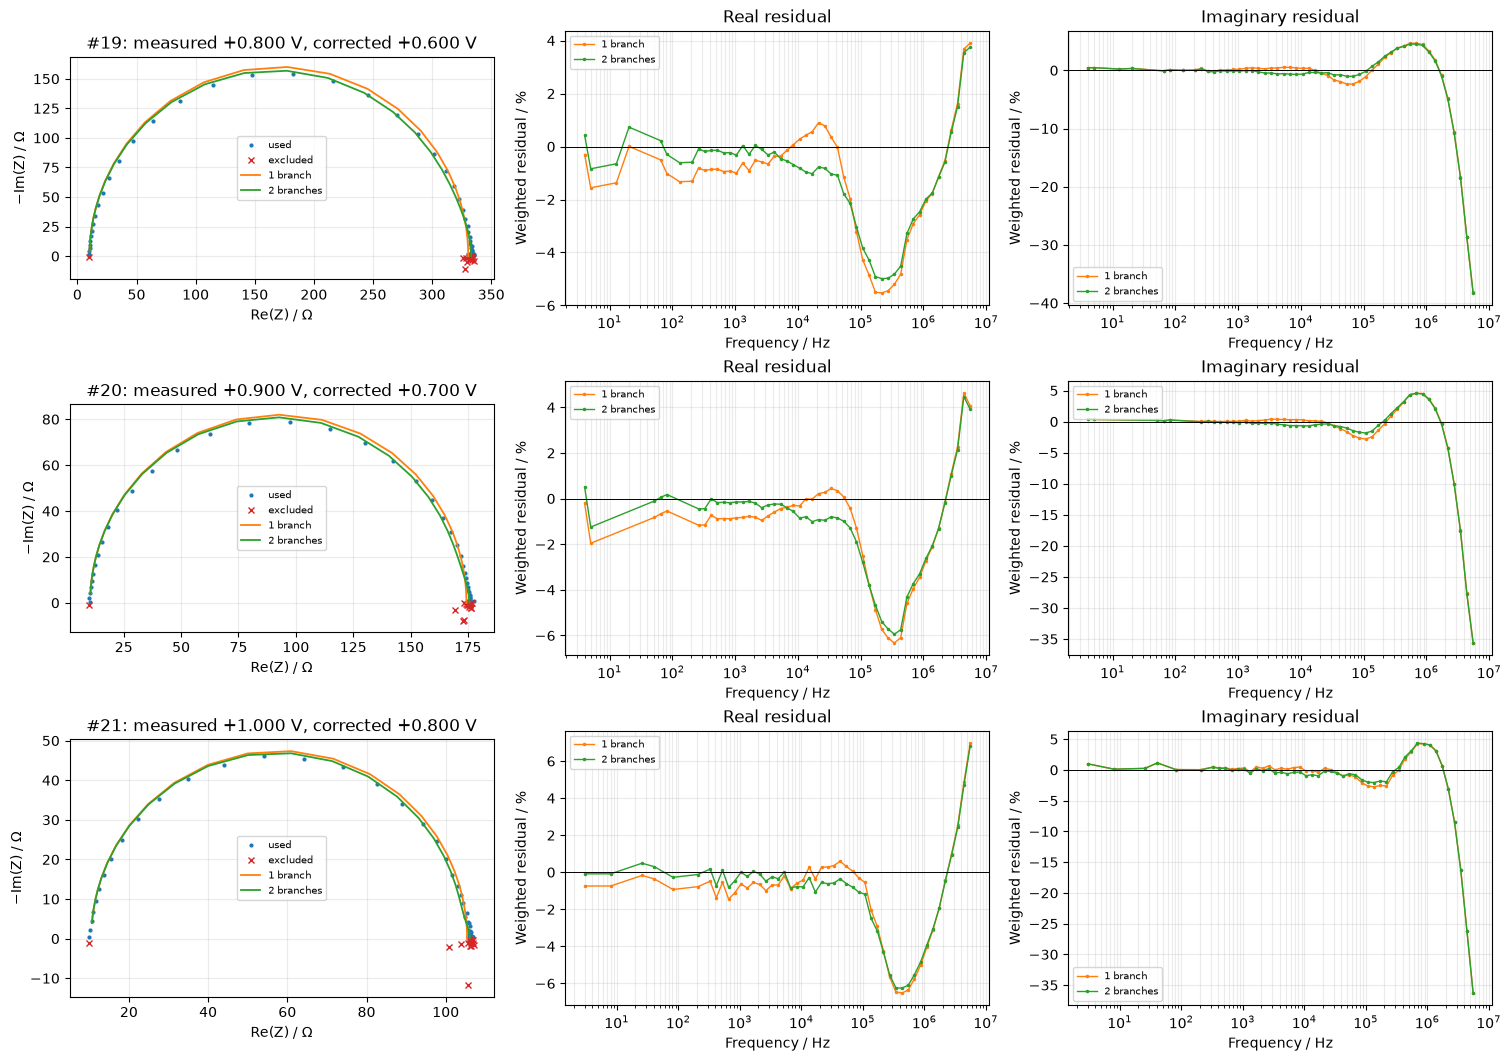

In [9]:
# Set the starting spectrum to review other blocks in larger datasets.
COMPARISON_START = 0
COMPARISON_LIMIT = 24  # maximum spectra rendered at once
COMPARISON_PER_FIGURE = 3
if COMPARISON_START < 0 or not 1 <= COMPARISON_LIMIT <= 24 or not 1 <= COMPARISON_PER_FIGURE <= 3:
    raise ValueError('Choose a nonnegative start, limit 1–24, and 1–3 spectra per figure.')
review_spectra = spectra[COMPARISON_START:COMPARISON_START + COMPARISON_LIMIT]
print(f'Showing {len(review_spectra)} of {len(spectra)} spectra; '
      f'start at spectrum index {COMPARISON_START}.')
if COMPARISON_START + COMPARISON_LIMIT < len(spectra):
    print('More spectra remain: increase COMPARISON_START and rerun this cell.')
comparison_rows = []
for spectrum in review_spectra:
    mask, one, two, metrics = fits[spectrum.spectrum_id]
    r1, r2 = metrics['single_relative_rmse'], metrics['voigt_relative_rmse']
    peaks = two.peaks_hz
    separation = (np.log10(peaks[1] / peaks[0]) if two.success and
                  np.isfinite(peaks).all() and min(peaks) > 0 else np.nan)
    comparison_rows.append({'spectrum_id': spectrum.spectrum_id,
        'measured_V': spectrum.voltage_v, 'corrected_V': spectrum.voltage_v + OFFSET_V,
        'used': int(mask.sum()), 'excluded': int((~mask).sum()),
        'single_RMSE_pct': 100 * r1, 'voigt_RMSE_pct': 100 * r2,
        'RMSE_reduction_pct': 100 * (r1 - r2) / r1 if np.isfinite(r1) and r1 > 0 and np.isfinite(r2) else np.nan,
        'delta_AICc': metrics['voigt_aicc'] - metrics['single_aicc'],
        'peak_separation_decades': separation, 'converged_starts': two.starts_converged,
        'near_best_starts': two.near_optimal_starts, 'voigt_flags': ', '.join(two.flags)})
comparison_review = pd.DataFrame(comparison_rows)
if not comparison_review.empty:
    display(comparison_review)
for start in range(0, len(review_spectra), COMPARISON_PER_FIGURE):
    group = review_spectra[start:start + COMPARISON_PER_FIGURE]
    fig, axes = plt.subplots(len(group), 3, figsize=(15, 3.5 * len(group)),
                             squeeze=False, constrained_layout=True)
    for axrow, spectrum in zip(axes, group):
        mask, one, two, metrics = fits[spectrum.spectrum_id]
        d = spectrum.data
        f = pd.to_numeric(d['freq/Hz'], errors='coerce').to_numpy(float)
        re = pd.to_numeric(d['Re(Z)/Ohm'], errors='coerce').to_numpy(float)
        neg_im = pd.to_numeric(d['-Im(Z)/Ohm'], errors='coerce').to_numpy(float)
        z = re - 1j * neg_im
        ax_n, ax_re, ax_im = axrow
        ax_n.plot(re[mask], neg_im[mask], '.', color='tab:blue', ms=4, label='used')
        ax_n.plot(re[~mask], neg_im[~mask], 'x', color='tab:red', ms=4, label='excluded')
        if np.any(mask):
            order = np.argsort(f[mask])
            freq, measured = f[mask][order], z[mask][order]
            for fit, model, label, color in ((one, impedance_rcpe, '1 branch', 'tab:orange'),
                                               (two, impedance_voigt, '2 branches', 'tab:green')):
                if not fit.success:
                    continue
                predicted = model(freq, *fit.parameters)
                floor = one.modulus_floor_ohm if one.modulus_floor_ohm is not None else max(1e-12 * np.median(np.abs(measured)), np.finfo(float).tiny)
                residual = 100 * (predicted - measured) / np.maximum(np.abs(measured), floor)
                ax_n.plot(predicted.real, -predicted.imag, '-', color=color, lw=1.3, label=label)
                ax_re.semilogx(freq, residual.real, '.-', color=color, ms=3, lw=1, label=label)
                ax_im.semilogx(freq, residual.imag, '.-', color=color, ms=3, lw=1, label=label)
        ax_n.set_aspect('equal', adjustable='box')
        ax_n.set(xlabel='Re(Z) / Ω', ylabel='−Im(Z) / Ω',
                 title=f'#{spectrum.spectrum_id}: measured {spectrum.voltage_v:+.3f} V, corrected {spectrum.voltage_v + OFFSET_V:+.3f} V')
        for ax, title in ((ax_re, 'Real residual'), (ax_im, 'Imaginary residual')):
            ax.axhline(0, color='black', lw=.7)
            ax.set(xlabel='Frequency / Hz', ylabel='Weighted residual / %', title=title)
        for ax in axrow:
            ax.grid(True, which='both', alpha=.25)
            ax.legend(fontsize=7)
    plt.show()
    plt.close(fig)

## 3. Visual and point-level audit

Change `PAGE` and rerun from configuration to inspect other spectra. Excluded points are marked separately where finite coordinates permit plotting. Residuals are $(Z_{model}-Z_{measured})/\max(|Z_{measured}|,\mathrm{floor})$; the solid curves use precisely the fitting frequencies.

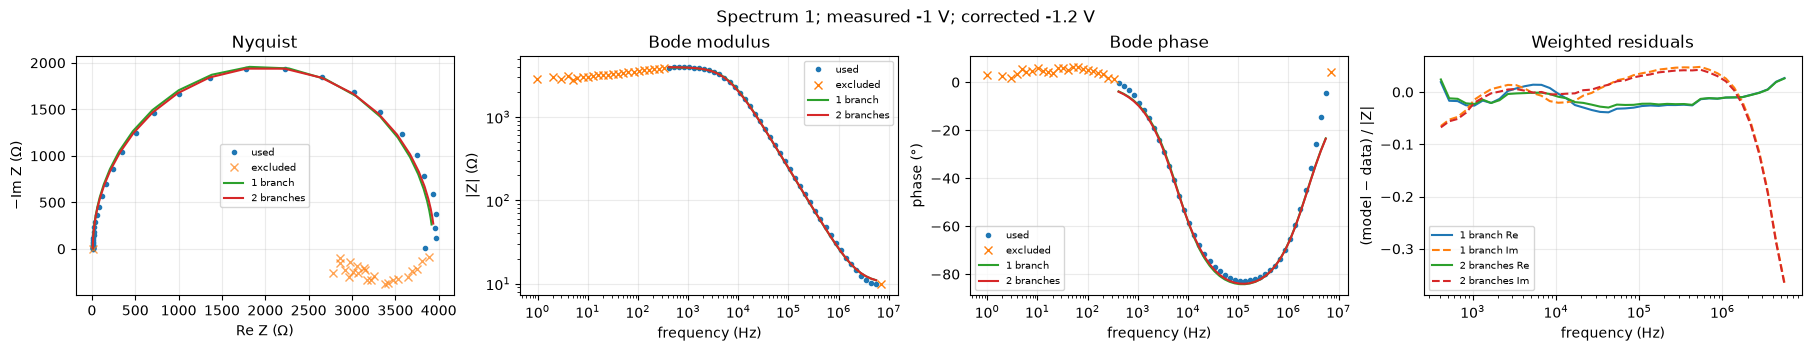

Spectrum 1: 42 used, 24 excluded; first 20 excluded records:


,_row,freq/Hz,Re(Z)/Ohm,-Im(Z)/Ohm,<Ewe>/V,used,reason
0,17881,7.000018e+06,9.878236,-0.730416,-1.000312,False,negative -Im(Z)
43,17924,3.286332e+02,3885.223100,-90.175003,-1.000325,False,negative -Im(Z)
44,17925,2.605840e+02,3806.222200,-126.848380,-1.000326,False,negative -Im(Z)
45,17926,2.066530e+02,3755.147700,-221.397540,-1.000293,False,negative -Im(Z)
46,17927,1.638986e+02,3693.355500,-235.823590,-1.000318,False,negative -Im(Z)
47,17928,1.299582e+02,3644.116900,-306.112790,-1.000328,False,negative -Im(Z)
48,17929,1.031190e+02,3529.978800,-322.874270,-1.000317,False,negative -Im(Z)
49,17930,8.175298e+01,3474.981400,-330.225860,-1.000313,False,negative -Im(Z)
50,17931,6.485470e+01,3412.597700,-369.402620,-1.000317,False,negative -Im(Z)
51,17932,5.143188e+01,3384.086200,-379.495480,-1.000314,False,negative -Im(Z)


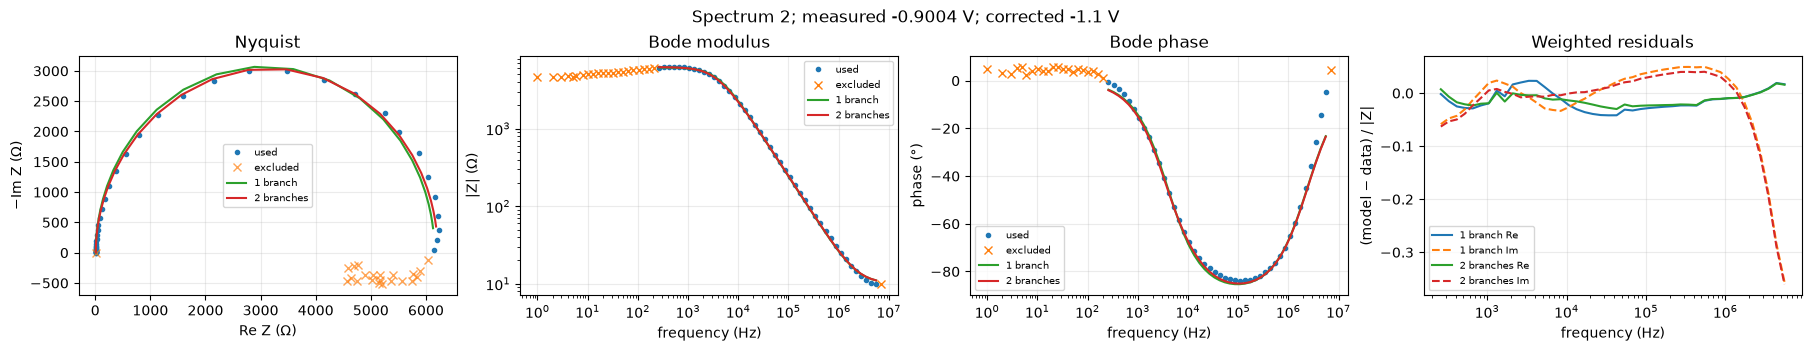

Spectrum 2: 44 used, 22 excluded; first 20 excluded records:


,_row,freq/Hz,Re(Z)/Ohm,-Im(Z)/Ohm,<Ewe>/V,used,reason
66,35837,7.000018e+06,9.851516,-0.789268,-0.900344,False,negative -Im(Z)
111,35882,2.066530e+02,6038.503400,-120.582530,-0.900333,False,negative -Im(Z)
112,35883,1.638986e+02,5898.255400,-303.193240,-0.900363,False,negative -Im(Z)
113,35884,1.299582e+02,5840.208500,-406.318210,-0.900366,False,negative -Im(Z)
114,35885,1.031190e+02,5767.536600,-346.952060,-0.900373,False,negative -Im(Z)
115,35886,8.175298e+01,5745.694300,-466.576900,-0.900371,False,negative -Im(Z)
116,35887,6.485470e+01,5570.993200,-470.032590,-0.900373,False,negative -Im(Z)
117,35888,5.143188e+01,5410.280300,-360.936430,-0.900369,False,negative -Im(Z)
118,35889,4.079633e+01,5364.910600,-465.743260,-0.900369,False,negative -Im(Z)
119,35890,3.234990e+01,5158.671400,-447.200740,-0.900378,False,negative -Im(Z)


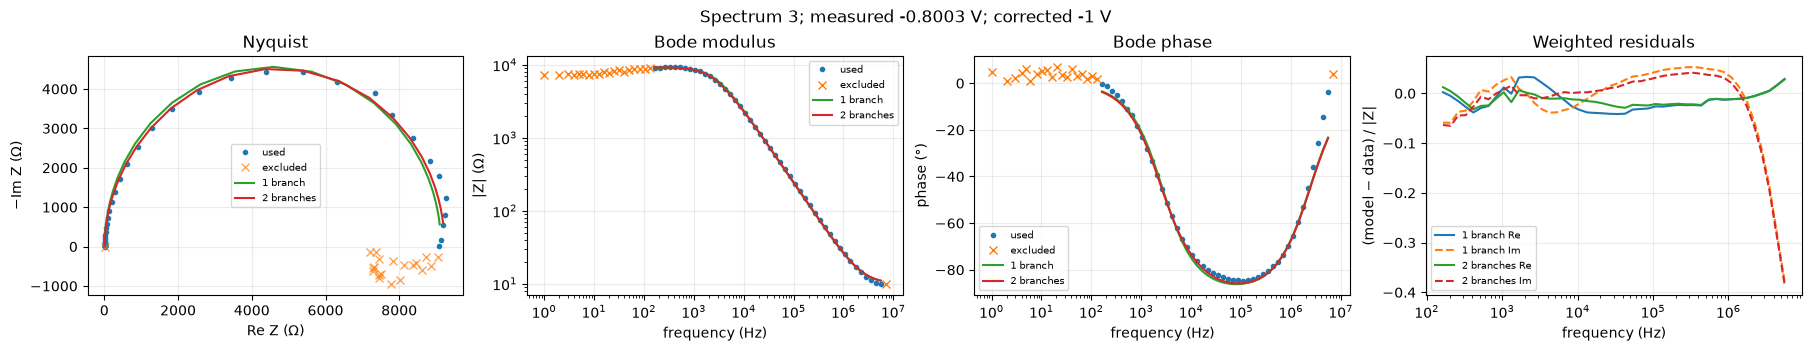

Spectrum 3: 46 used, 20 excluded; first 20 excluded records:


,_row,freq/Hz,Re(Z)/Ohm,-Im(Z)/Ohm,<Ewe>/V,used,reason
132,53856,7.000018e+06,9.881989,-0.70302,-0.800260,False,negative -Im(Z)
179,53903,1.299582e+02,9038.555700,-268.10422,-0.800276,False,negative -Im(Z)
180,53904,1.031190e+02,8872.380900,-498.90692,-0.800271,False,negative -Im(Z)
181,53905,8.175298e+01,8726.927700,-277.50601,-0.800264,False,negative -Im(Z)
182,53906,6.485470e+01,8612.209000,-586.82880,-0.800268,False,negative -Im(Z)
183,53907,5.143188e+01,8369.617200,-479.13019,-0.800269,False,negative -Im(Z)
184,53908,4.079633e+01,8021.161600,-845.50598,-0.800265,False,negative -Im(Z)
185,53909,3.234990e+01,8455.158200,-414.78198,-0.800266,False,negative -Im(Z)
186,53910,2.566524e+01,8135.792500,-480.64017,-0.800270,False,negative -Im(Z)
187,53911,2.035834e+01,7774.819300,-954.92535,-0.800270,False,negative -Im(Z)


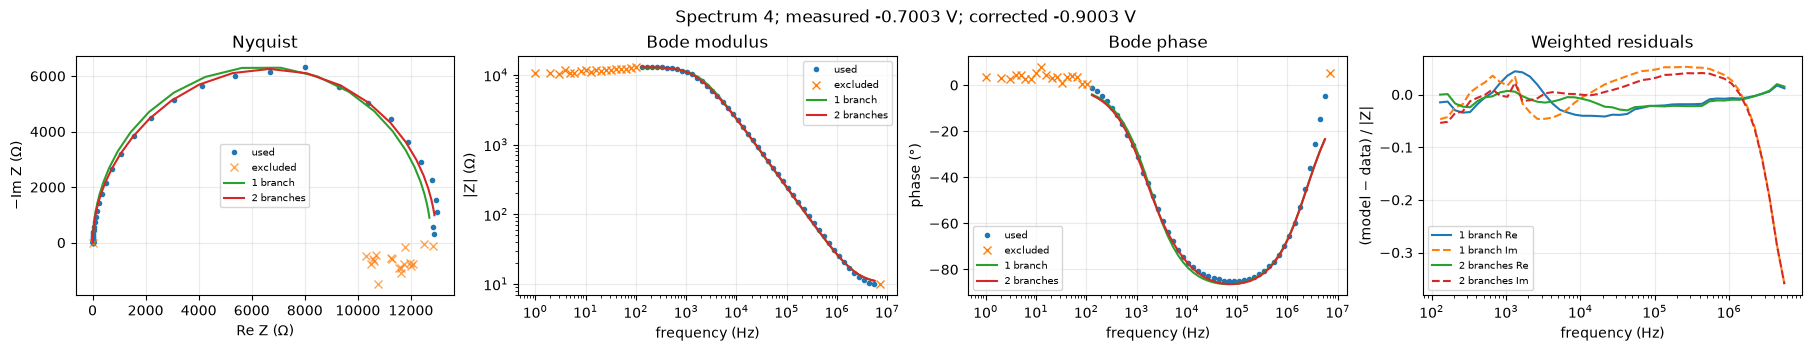

Spectrum 4: 47 used, 19 excluded; first 20 excluded records:


,_row,freq/Hz,Re(Z)/Ohm,-Im(Z)/Ohm,<Ewe>/V,used,reason
198,71877,7.000018e+06,9.858063,-0.878339,-0.700305,False,negative -Im(Z)
246,71925,1.031190e+02,12843.291000,-116.917120,-0.700320,False,negative -Im(Z)
247,71926,8.175298e+01,12488.958000,-66.198029,-0.700325,False,negative -Im(Z)
248,71927,6.485470e+01,12095.550000,-764.397340,-0.700326,False,negative -Im(Z)
249,71928,5.143188e+01,12010.203000,-848.087770,-0.700318,False,negative -Im(Z)
250,71929,4.079633e+01,11964.348000,-734.468510,-0.700330,False,negative -Im(Z)
251,71930,3.234990e+01,11772.510000,-171.771210,-0.700317,False,negative -Im(Z)
252,71931,2.566524e+01,11730.542000,-760.585630,-0.700323,False,negative -Im(Z)
253,71932,2.035834e+01,11280.902000,-571.003480,-0.700331,False,negative -Im(Z)
254,71933,1.614154e+01,11623.146000,-923.927120,-0.700328,False,negative -Im(Z)


In [6]:
for s in spectra[PAGE*PAGE_SIZE:(PAGE+1)*PAGE_SIZE]:
    mask, one, two, comp = fits[s.spectrum_id]
    d = s.data
    f = pd.to_numeric(d['freq/Hz'], errors='coerce').to_numpy(float)
    re = pd.to_numeric(d['Re(Z)/Ohm'], errors='coerce').to_numpy(float)
    im = pd.to_numeric(d['-Im(Z)/Ohm'], errors='coerce').to_numpy(float)
    z = re - 1j*im
    fig, axes = plt.subplots(1, 4, figsize=(18, 3.4), constrained_layout=True)
    axes[0].plot(re[mask], im[mask], '.', label='used')
    axes[0].plot(re[~mask], im[~mask], 'x', label='excluded', alpha=.7)
    axes[1].loglog(f[mask], np.abs(z[mask]), '.', label='used')
    axes[1].loglog(f[~mask], np.abs(z[~mask]), 'x', label='excluded')
    axes[2].semilogx(f[mask], np.angle(z[mask], deg=True), '.', label='used')
    axes[2].semilogx(f[~mask], np.angle(z[~mask], deg=True), 'x', label='excluded')
    for result, model, label in ((one, impedance_rcpe, '1 branch'), (two, impedance_voigt, '2 branches')):
        if result.success:
            order = np.argsort(f[mask])
            ff, zz = f[mask][order], z[mask][order]
            pred = model(ff, *result.parameters)
            weights = np.maximum(np.abs(zz), max(1e-12*np.median(np.abs(zz)), np.finfo(float).tiny))
            residual = (pred-zz)/weights
            axes[0].plot(pred.real, -pred.imag, label=label)
            axes[1].loglog(ff, np.abs(pred), label=label)
            axes[2].semilogx(ff, np.angle(pred, deg=True), label=label)
            axes[3].semilogx(ff, residual.real, label=label+' Re')
            axes[3].semilogx(ff, residual.imag, '--', label=label+' Im')
    for ax, title, xlabel, ylabel in zip(axes, ['Nyquist', 'Bode modulus', 'Bode phase', 'Weighted residuals'],
        ['Re Z (Ω)', 'frequency (Hz)', 'frequency (Hz)', 'frequency (Hz)'],
        ['−Im Z (Ω)', '|Z| (Ω)', 'phase (°)', '(model − data) / |Z|']):
        ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
        ax.grid(True, alpha=.25)
        ax.legend(fontsize=7)
    fig.suptitle(f'Spectrum {s.spectrum_id}; measured {s.voltage_v:.4g} V; corrected {s.voltage_v+OFFSET_V:.4g} V')
    plt.show()
    audit = d[['_row', 'freq/Hz', 'Re(Z)/Ohm', '-Im(Z)/Ohm', '<Ewe>/V']].copy()
    reasons = []
    for fi, ri, ii in zip(f, re, im):
        tags = []
        if not np.isfinite(fi) or fi <= 0: tags.append('invalid frequency')
        if not np.isfinite(ri) or not np.isfinite(ii): tags.append('invalid impedance')
        if np.isfinite(ii) and ii < 0: tags.append('negative -Im(Z)')
        if np.isfinite(fi) and ((FREQ_MIN_HZ is not None and fi < FREQ_MIN_HZ) or
                                (FREQ_MAX_HZ is not None and fi > FREQ_MAX_HZ)):
            tags.append('outside selected frequency band')
        reasons.append('; '.join(tags) if tags else 'used')
    audit['used'], audit['reason'] = mask, reasons
    print(f'Spectrum {s.spectrum_id}: {mask.sum()} used, {(~mask).sum()} excluded; first 20 excluded records:')
    display(audit.loc[~audit.used].head(20))

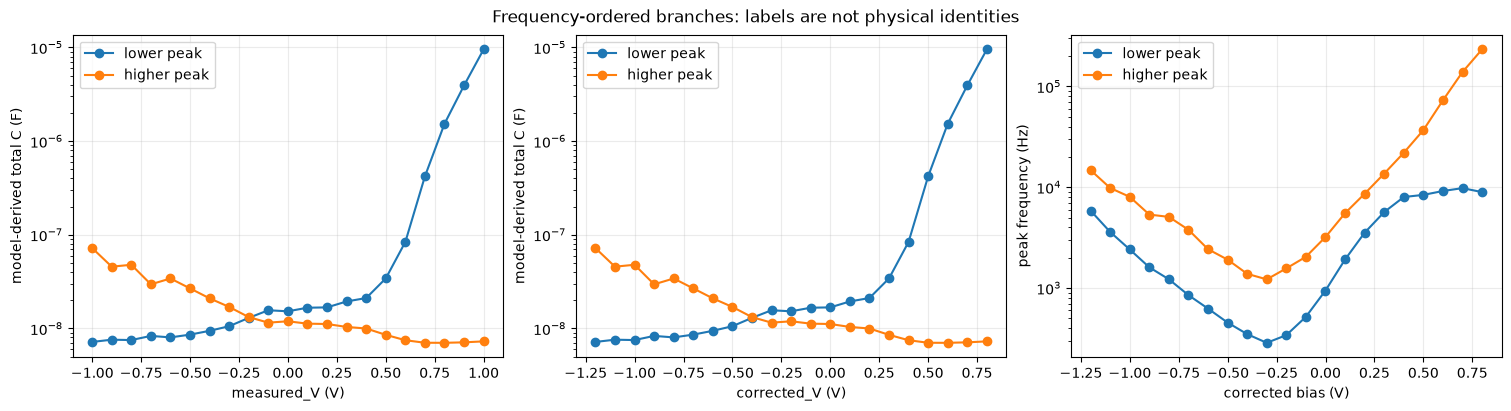

In [7]:
if not results.empty:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
    for suffix, label in [('low', 'lower peak'), ('high', 'higher peak')]:
        for ax, xcol in zip(axes[:2], ['measured_V', 'corrected_V']):
            ax.plot(results[xcol], results[f'C_{suffix}_F'], 'o-', label=label)
            ax.set_yscale('log')
            ax.set(xlabel=xcol+' (V)', ylabel='model-derived total C (F)')
        axes[2].plot(results['corrected_V'], results[f'peak_{suffix}_Hz'], 'o-', label=label)
    axes[2].set(xlabel='corrected bias (V)', ylabel='peak frequency (Hz)', yscale='log')
    for ax in axes:
        ax.grid(True, alpha=.25)
        ax.legend()
    fig.suptitle('Frequency-ordered branches: labels are not physical identities')
    plt.show()

## 4. Review-gated exploratory regression

Default: no branch assignment, no regression and no density. After reviewing **all** pages, enter a branch, a substantive justification, and an inclusive corrected-bias range in `REVIEW`; confirm branch and range. QC-blocked spectra remain reported and are excluded from regression. This conservative gate does not turn the remaining fitted capacitance into depletion capacitance. Density needs a separate explicit confirmation of the model, active area, and permittivity assumptions. OLS uncertainty is residual-based, ignores correlations and area/permittivity systematic errors, and the intercept is only an algebraic extrapolation, not a flat-band assignment.

In [8]:
BLOCKING = {'invalid_impedance_or_frequency', 'invalid_voltage', 'voltage_spread',
    'too_few_distinct_frequencies', 'frequency_reversal', 'incomplete_sweep', 'missing_cycle',
    'poor_relative_fit', 'parameter_at_bound', 'ill_conditioned', 'near_optimal_parameter_ambiguity',
    'overlapping_peaks', 'peak_outside_measured_band', 'multistart_unverified',
    'possible_branch_crossing', 'capacitance_or_uncertainty_unavailable'}
regression = density = None
if not REVIEW['confirm_branch_and_range']:
    print('REVIEW REQUIRED: no branch/range confirmed; regression and density not calculated.')
elif (REVIEW['branch'] not in (1, 2) or not isinstance(REVIEW['justification'], str)
      or len(REVIEW['justification'].strip()) < 10 or REVIEW['voltage_range_corrected'] is None):
    print('REVIEW REQUIRED: provide branch 1/2, justification (at least 10 characters), and corrected range.')
elif results.empty:
    print('No spectra available for regression.')
else:
    limits = np.asarray(REVIEW['voltage_range_corrected'], dtype=float)
    if limits.shape != (2,) or not np.isfinite(limits).all() or limits[0] >= limits[1]:
        raise ValueError('Corrected range must be two finite, increasing inclusive limits.')
    col = 'C_low_F' if REVIEW['branch'] == 1 else 'C_high_F'
    audit = results.copy()
    audit['blocking_flags'] = audit['flags'].apply(lambda x: '; '.join(sorted(set(x.split('; ')) & BLOCKING)))
    audit['in_range'] = audit['corrected_V'].between(*limits, inclusive='both')
    audit['eligible'] = (audit['in_range'] & audit['voigt_ok'] & audit['blocking_flags'].eq('') &
                         np.isfinite(pd.to_numeric(audit[col], errors='coerce')) & (audit[col] > 0))
    selected = audit.loc[audit['eligible']].copy()
    print('Branch justification:', REVIEW['justification'])
    print(f'Range audit: {audit.in_range.sum()} in range, {len(selected)} eligible, '
          f'{(audit.in_range & ~audit.eligible).sum()} blocked; table page {PAGE}.')
    display(audit.loc[audit.in_range, ['spectrum_id','measured_V','corrected_V',col,'eligible','blocking_flags','flags']]
            .iloc[PAGE*TABLE_PAGE_SIZE:(PAGE+1)*TABLE_PAGE_SIZE])
    if len(selected) < 4 or selected.corrected_V.nunique() < 4:
        print('REVIEW REQUIRED: at least four eligible spectra at distinct voltages are needed; no regression or density.')
    else:
        x = selected['corrected_V'].to_numpy(float)
        y, _ = inverse_capacitance_squared(selected[col].to_numpy(float))
        regression = linear_regression(x, y)
        print('Included spectrum IDs:', selected.spectrum_id.tolist())
        print(f'Slope = {regression.slope:.6g} ± {np.sqrt(regression.covariance[0,0]):.3g} F⁻²/V; '
              f'intercept = {regression.intercept:.6g} F⁻²; R² = {regression.r_squared:.5g}; RMSE = {regression.rmse:.5g}.')
        print('Algebraic x-intercept (V) and residual-based standard error:', regression.x_intercept_v, regression.x_intercept_std_v)
        print('Regression flags:', regression.flags, '(intercept is not assigned as flat-band).')
        fig, ax = plt.subplots(figsize=(6, 4))
        ax.plot(x, y, 'o', label='included spectra')
        xx = np.linspace(x.min(), x.max(), 100)
        ax.plot(xx, regression.slope*xx+regression.intercept, label='unweighted OLS in range')
        ax.set(xlabel='corrected bias (V)', ylabel='1 / C² (F⁻²)')
        ax.grid(True, alpha=.25); ax.legend(); plt.show()
        if REVIEW['confirm_density_assumptions'] is True:
            try:
                density = carrier_density(regression, area_m2=AREA_CM2*1e-4,
                                          relative_permittivity=RELATIVE_PERMITTIVITY, confirmed=True)
                print('Conditional effective density; uncertainty from OLS slope only:', density)
            except ValueError as exc:
                print('Density unavailable:', exc)
        else:
            print('Density withheld: physical assumptions have not been independently confirmed.')

REVIEW REQUIRED: no branch/range confirmed; regression and density not calculated.


### Next steps

Review every page and the QC flags before considering any branch assignment. The default configuration intentionally produces neither a regression nor a density. If the selected spectra are QC-blocked, the analysis remains stopped even after confirmation; revisit the model or data rather than treating an optimizer result as a physical identification.